PART 1: EIGENVALUE DISTRIBUTIONS (Connectome-Like)

Analyzing: Scenario A: Border of Cone


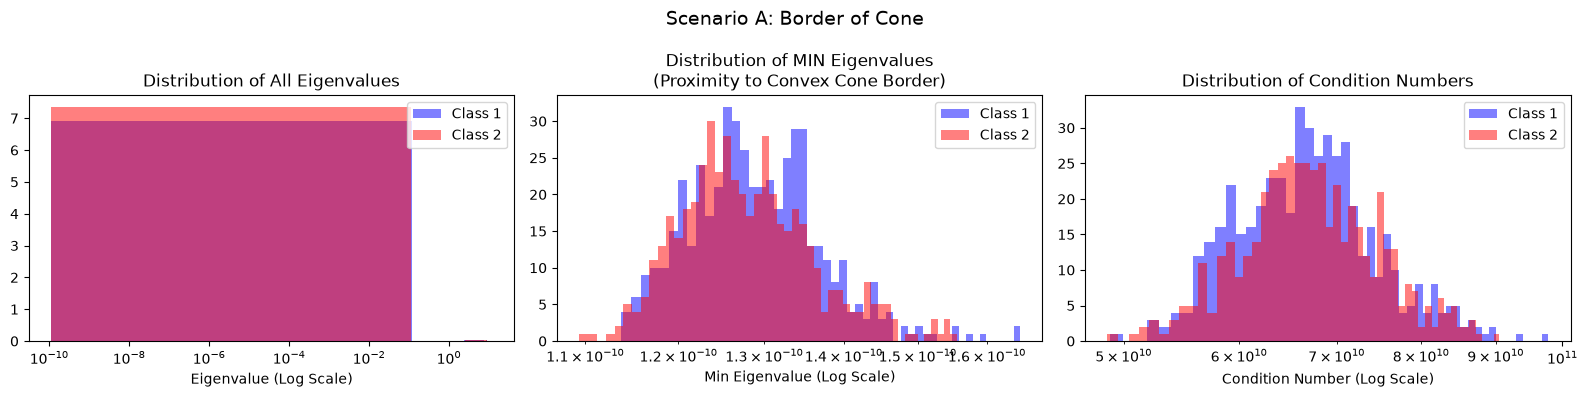

  Class 1 -> Min Eig: 1.14e-10 | Max Eig: 1.19e+01 | Med Cond: 6.73e+10
  Class 2 -> Min Eig: 1.09e-10 | Max Eig: 1.11e+01 | Med Cond: 6.73e+10

Analyzing: Scenario B: Moderate Distance


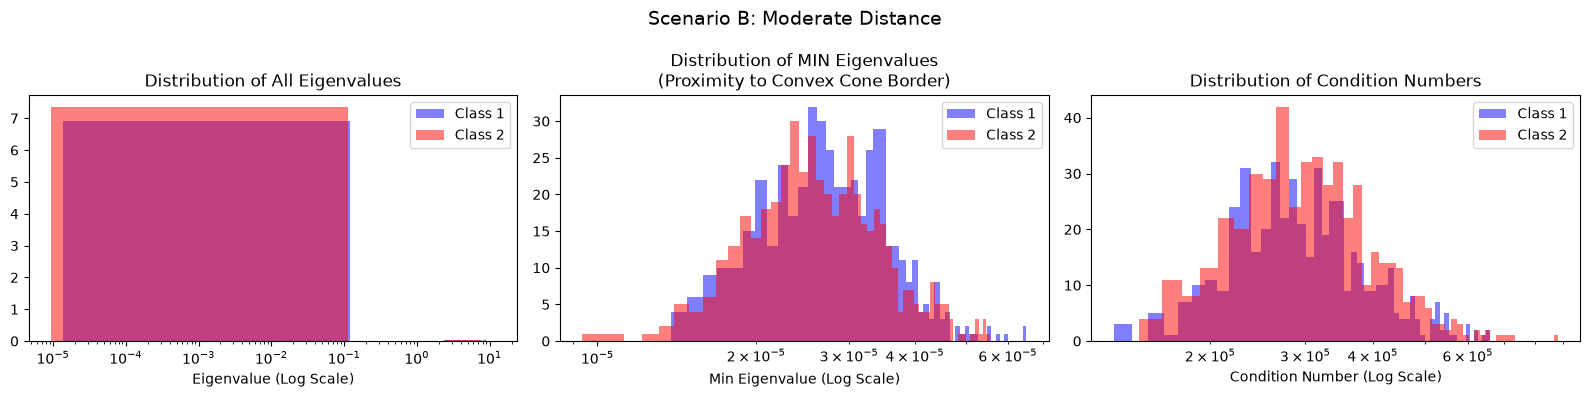

  Class 1 -> Min Eig: 1.38e-05 | Max Eig: 1.19e+01 | Med Cond: 3.05e+05
  Class 2 -> Min Eig: 9.36e-06 | Max Eig: 1.11e+01 | Med Cond: 3.16e+05

Analyzing: Scenario C: Deep Inside Cone


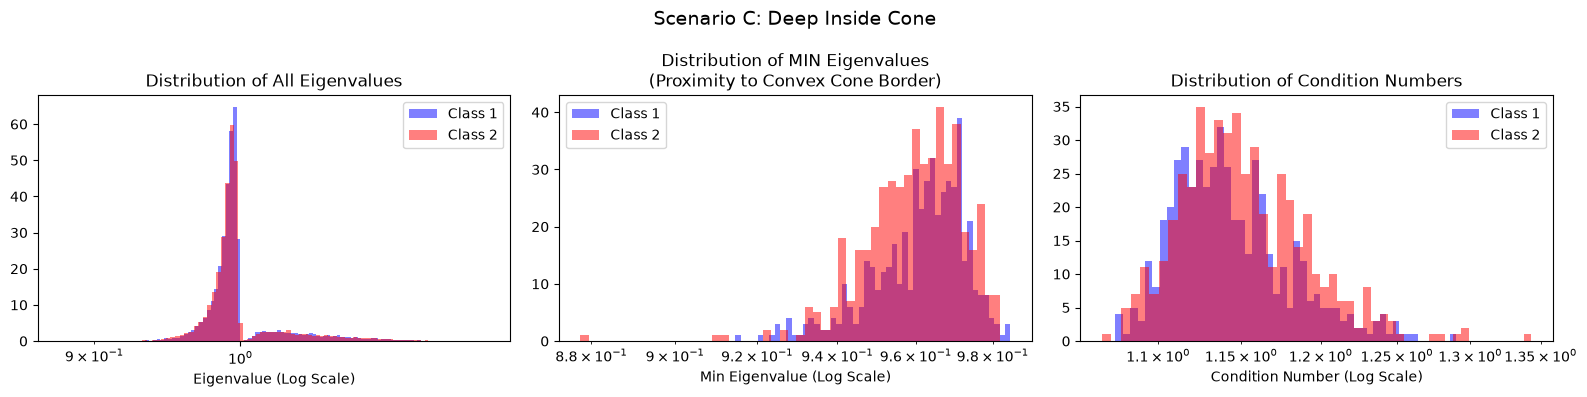

  Class 1 -> Min Eig: 9.15e-01 | Max Eig: 1.18e+00 | Med Cond: 1.14e+00
  Class 2 -> Min Eig: 8.77e-01 | Max Eig: 1.20e+00 | Med Cond: 1.15e+00

PART 2: CLASSIFICATION (2D Embeddings)
Method          | Border (A) Mean ± Std  | Moderate (B) Mean ± Std | Deep Inside (C) Mean ± Std
------------------------------------------------------------------------------------------
Tangent PCA     |  47.15 ± 3.91           |  51.35 ± 4.39           |  49.75 ± 4.22           | 
Classic PCA     |  49.15 ± 1.99           |  49.25 ± 1.82           |  49.15 ± 4.32           | 


In [ ]:
    import numpy as np
    from scipy.linalg import expm
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.metrics import accuracy_score
    import matplotlib.pyplot as plt

    # ===============================================================
    # 1. Realistic Connectome-Like Data Generation
    # ===============================================================
    def generate_connectome_data(n_samples_per_class=500, dim=28, 
                                noise_level=1e-6, class_shift=0.0, seed=42):
        """
        Generates SPD matrices resembling brain connectomes.
        - Diagonal is forced to 1.0 (Correlation matrices).
        - Uses a factor model to create network structure.
        - noise_level controls proximity to the convex cone border.
        Small noise -> eigenvalues close to 0 (Border).
        Large noise -> eigenvalues large (Inside).
        """
        rng = np.random.default_rng(seed)
        X, y = [], []
        
        for c in range(2):
            for _ in range(n_samples_per_class):
                # 1. Latent brain networks (rank 5)
                F = rng.standard_normal((dim, 5)) * (1.0 + class_shift * c)
                # 2. Unique noise (controls condition number / proximity to border)
                psi = rng.uniform(0.1, 1.0, size=dim) * noise_level
                
                # 3. Covariance structure
                Cov = F @ F.T + np.diag(psi)
                
                # 4. Convert to Correlation Matrix (forces diagonal to 1)
                d = np.sqrt(np.diag(Cov))
                Corr = Cov / np.outer(d, d)
                
                # 5. Ensure perfect symmetry and SPD
                Corr = 0.5 * (Corr + Corr.T)
                Corr += np.eye(dim) * 1e-10 # tiny jitter for strict PD
                
                X.append(Corr)
                y.append(c)
                
        return np.stack(X), np.array(y)

    # ===============================================================
    # 2. Visualization Dashboard
    # ===============================================================
    def visualize_connectome_case(name, noise_level, class_shift):
        print(f"\nAnalyzing: {name}")
        
        X, y = generate_connectome_data(n_samples_per_class=500, dim=28, 
                                        noise_level=noise_level, class_shift=class_shift)
        
        eigs = np.linalg.eigvalsh(X)
        
        max_eigs_c1 = eigs[y==0][:, -1]
        max_eigs_c2 = eigs[y==1][:, -1]
        min_eigs_c1 = eigs[y==0][:, 0]
        min_eigs_c2 = eigs[y==1][:, 0]
        
        cond_c1 = max_eigs_c1 / np.clip(min_eigs_c1, 1e-15, None)
        cond_c2 = max_eigs_c2 / np.clip(min_eigs_c2, 1e-15, None)

        fig, axes = plt.subplots(1, 3, figsize=(16, 4))
        
        # Plot 1: All Eigenvalues (Log Scale)
        axes[0].hist(eigs[y==0].flatten(), bins=100, alpha=0.5, label='Class 1', color='blue', density=True)
        axes[0].hist(eigs[y==1].flatten(), bins=100, alpha=0.5, label='Class 2', color='red', density=True)
        axes[0].set_title("Distribution of All Eigenvalues")
        axes[0].set_xlabel("Eigenvalue (Log Scale)")
        axes[0].set_xscale('log')
        axes[0].legend()
        
        # Plot 2: Min Eigenvalues (Log Scale) -> Shows distance to boundary
        axes[1].hist(min_eigs_c1, bins=50, alpha=0.5, label='Class 1', color='blue')
        axes[1].hist(min_eigs_c2, bins=50, alpha=0.5, label='Class 2', color='red')
        axes[1].set_title("Distribution of MIN Eigenvalues\n(Proximity to Convex Cone Border)")
        axes[1].set_xlabel("Min Eigenvalue (Log Scale)")
        axes[1].set_xscale('log')
        axes[1].legend()
        
        # Plot 3: Condition Numbers
        axes[2].hist(cond_c1, bins=50, alpha=0.5, label='Class 1', color='blue')
        axes[2].hist(cond_c2, bins=50, alpha=0.5, label='Class 2', color='red')
        axes[2].set_title("Distribution of Condition Numbers")
        axes[2].set_xlabel("Condition Number (Log Scale)")
        axes[2].set_xscale('log')
        axes[2].legend()
        
        plt.suptitle(f"{name}", fontsize=14)
        plt.tight_layout()
        plt.show()
        
        print(f"  Class 1 -> Min Eig: {min_eigs_c1.min():.2e} | Max Eig: {max_eigs_c1.max():.2e} | Med Cond: {np.median(cond_c1):.2e}")
        print(f"  Class 2 -> Min Eig: {min_eigs_c2.min():.2e} | Max Eig: {max_eigs_c2.max():.2e} | Med Cond: {np.median(cond_c2):.2e}")

    # ===============================================================
    # 3. SPD Primitives & PCA
    # ===============================================================
    def batch_spd_sqrt(M):
        w, V = np.linalg.eigh(M); w = np.clip(w, 1e-15, None)
        return np.einsum('nij,nj,nkj->nik', V, np.sqrt(w), V)

    def batch_spd_inv_sqrt(M):
        w, V = np.linalg.eigh(M); w = np.clip(w, 1e-15, None)
        return np.einsum('nij,nj,nkj->nik', V, 1.0 / np.sqrt(w), V)

    def batch_spd_log(M):
        w, V = np.linalg.eigh(M); w = np.clip(w, 1e-15, None)
        return np.einsum('nij,nj,nkj->nik', V, np.log(w), V)

    def spd_frechet_mean(mats, tol=1e-8, max_iter=30):
        M = mats.mean(axis=0)
        for _ in range(max_iter):
            M_sqrt = batch_spd_sqrt(M[None, :, :])[0]
            Mi = batch_spd_inv_sqrt(M[None, :, :])[0]
            T = batch_spd_log(Mi @ mats @ Mi).mean(axis=0)
            
            w, V = np.linalg.eigh(T)
            M = M_sqrt @ (V * np.exp(w)) @ V.T @ M_sqrt
            M = 0.5 * (M + M.T)
            
            if np.linalg.norm(T) < tol: break
        return M

    def fit_tangent_pca(spd_mats, k):
        mean = spd_frechet_mean(spd_mats)
        mean_inv_sqrt = batch_spd_inv_sqrt(mean[None, :, :])[0]
        tangents = batch_spd_log(mean_inv_sqrt @ spd_mats @ mean_inv_sqrt)
        
        d = tangents.shape[1]; iu = np.triu_indices(d)
        T_vec = tangents[:, iu[0], iu[1]]
        
        t_mean = T_vec.mean(axis=0)
        _, _, Vt = np.linalg.svd(T_vec - t_mean, full_matrices=False)
        return mean, Vt[:k], t_mean, iu

    def transform_tangent(spd_mats, mean_spd, comps, t_mean, iu):
        mean_inv_sqrt = batch_spd_inv_sqrt(mean_spd[None, :, :])[0]
        tangents = batch_spd_log(mean_inv_sqrt @ spd_mats @ mean_inv_sqrt)
        return (tangents[:, iu[0], iu[1]] - t_mean) @ comps.T

    def fit_pca_spd(spd_mats, k):
        N = spd_mats.shape[0]
        X_vec = spd_mats.reshape(N, -1) 
        X_mean = X_vec.mean(axis=0)
        _, _, Vt = np.linalg.svd(X_vec - X_mean, full_matrices=False)
        return X_mean, Vt[:k]

    def transform_pca_spd(spd_mats, mean_vec, comps):
        N = spd_mats.shape[0]
        X_vec = spd_mats.reshape(N, -1)
        return (X_vec - mean_vec) @ comps.T

    # ===============================================================
    # 4. Run
    # ===============================================================
    # Scenario 1: All eigenvalues close to zero (On the border)
    # Scenario 2: Some close to zero, some not (Moderate distance)
    # Scenario 3: No eigenvalues close to zero (Far from border)
    scenarios = [
        ("Scenario A: Border of Cone", 1e-9, 0.025),
        ("Scenario B: Moderate Distance", 1e-3, 0.025),
        ("Scenario C: Deep Inside Cone", 1e+3, 0.025)
    ]

    if __name__ == "__main__":
        print("="*60)
        print("PART 1: EIGENVALUE DISTRIBUTIONS (Connectome-Like)")
        print("="*60)
        for name, noise, shift in scenarios:
            visualize_connectome_case(name, noise, shift)
            
        print("\n" + "="*60)
        print("PART 2: CLASSIFICATION (2D Embeddings)")
        print("="*60)
        
        N_RUNS = 10
        results = {m: {c: [] for c, _, _ in scenarios} for m in ["Tangent PCA", "Classic PCA"]}

        for name, noise, shift in scenarios:
            X, y = generate_connectome_data(500, 28, noise, shift)
            
            for run in range(N_RUNS):
                idx_tr, idx_te = train_test_split(
                    np.arange(len(y)), test_size=0.2, random_state=run, stratify=y
                )
                X_tr, y_tr = X[idx_tr], y[idx_tr]
                X_te, y_te = X[idx_te], y[idx_te]
                
                # Classic PCA
                mv, cp = fit_pca_spd(X_tr, 2)
                acc_p = accuracy_score(y_te, KNeighborsClassifier(n_neighbors=5)
                                    .fit(transform_pca_spd(X_tr, mv, cp), y_tr)
                                    .predict(transform_pca_spd(X_te, mv, cp)))
                results["Classic PCA"][name].append(acc_p * 100)
                
                # Tangent PCA
                ms, ct, tm, iu = fit_tangent_pca(X_tr, 2)
                acc_t = accuracy_score(y_te, KNeighborsClassifier(n_neighbors=5)
                                    .fit(transform_tangent(X_tr, ms, ct, tm, iu), y_tr)
                                    .predict(transform_tangent(X_te, ms, ct, tm, iu)))
                results["Tangent PCA"][name].append(acc_t * 100)

        print(f"{'Method':<15} | {'Border (A) Mean ± Std':<22} | {'Moderate (B) Mean ± Std':<22} | {'Deep Inside (C) Mean ± Std':<22}")
        print("-" * 90)
        for method in ["Tangent PCA", "Classic PCA"]:
            row_str = f"{method:<15} | "
            for name, _, _ in scenarios:
                accs = results[method][name]
                row_str += f"{np.mean(accs):>6.2f} ± {np.std(accs):<6.2f}         | "
            print(row_str)

PART 2 (extended): CLASSIFICATION ACCURACY (%)  -- mean ± std over 10 runs
Method         | A: Border of Cone      | B: Moderate Distance   | C: Deep Inside Cone   
----------------------------------------------------------------------------------------------------
[running] A: Border of Cone (noise=1e-09)
[running] B: Moderate Distance (noise=0.001)
[running] C: Deep Inside Cone (noise=1000.0)
----------------------------------------------------------------------------------------------------
Baseline       |  47.15 ± 3.91       |  51.35 ± 4.39       |  49.75 ± 4.22       | 
M1 DiagLoad    |  47.50 ± 4.05       |  48.45 ± 3.57       |  49.70 ± 4.29       | 
M2 EigFloor    |  47.50 ± 3.98       |  48.90 ± 2.44       |  49.75 ± 4.22       | 
M3 MeanReg     |  49.35 ± 2.04       |  50.90 ± 3.52       |  49.75 ± 4.22       | 


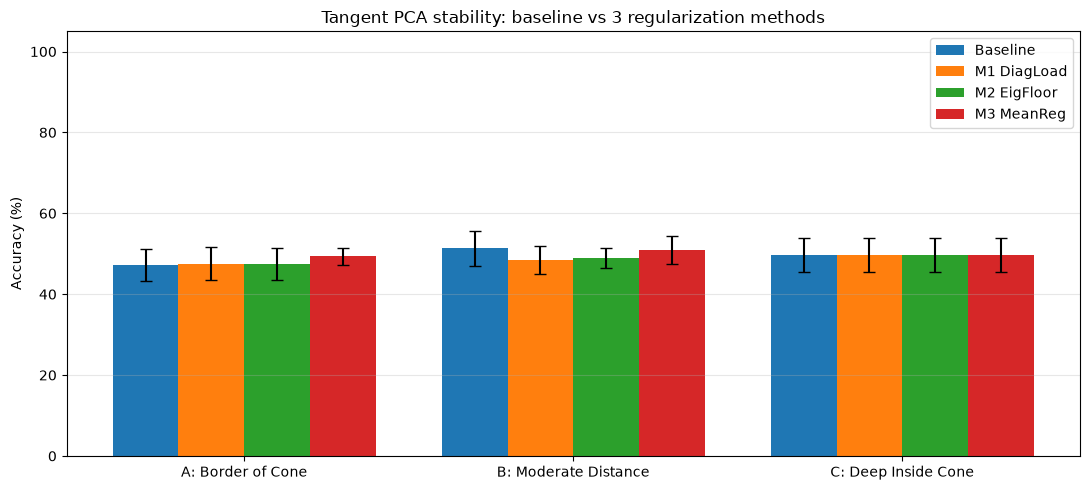

In [70]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# ===============================================================
# 1. Realistic Connectome-Like Data Generation  (UNCHANGED)
# ===============================================================
def generate_connectome_data(n_samples_per_class=500, dim=28,
                             noise_level=1e-6, class_shift=0.0, seed=42):
    rng = np.random.default_rng(seed)
    X, y = [], []
    for c in range(2):
        for _ in range(n_samples_per_class):
            F = rng.standard_normal((dim, 5)) * (1.0 + class_shift * c)
            psi = rng.uniform(0.1, 1.0, size=dim) * noise_level
            Cov = F @ F.T + np.diag(psi)
            d = np.sqrt(np.diag(Cov))
            Corr = Cov / np.outer(d, d)
            Corr = 0.5 * (Corr + Corr.T)
            Corr += np.eye(dim) * 1e-10
            X.append(Corr); y.append(c)
    return np.stack(X), np.array(y)

# ===============================================================
# 2. SPD primitives (with configurable floor)
# ===============================================================
def batch_spd_sqrt(M, floor=1e-15):
    w, V = np.linalg.eigh(M); w = np.clip(w, floor, None)
    return np.einsum('nij,nj,nkj->nik', V, np.sqrt(w), V)

def batch_spd_inv_sqrt(M, floor=1e-15):
    w, V = np.linalg.eigh(M); w = np.clip(w, floor, None)
    return np.einsum('nij,nj,nkj->nik', V, 1.0 / np.sqrt(w), V)

def batch_spd_log(M, floor=1e-15):
    w, V = np.linalg.eigh(M); w = np.clip(w, floor, None)
    return np.einsum('nij,nj,nkj->nik', V, np.log(w), V)

# ===============================================================
# 3. Three regularization methods on a batch of SPD matrices
# ===============================================================
def diag_loading(M, eps):
    """M1: C_i <- C_i + eps*I"""
    I = np.eye(M.shape[-1])
    return M + eps * I

def eig_flooring(M, tau):
    """M2: eigenvalues floored at tau, reconstruct."""
    w, V = np.linalg.eigh(M)
    w = np.maximum(w, tau)
    return np.einsum('nij,nj,nkj->nik', V, w, V)

# M3 is applied inside fit_tangent_pca (mean only) — see below.

# ===============================================================
# 4. Tangent PCA (baseline + optional mean regularization)
# ===============================================================
def spd_frechet_mean(mats, tol=1e-8, max_iter=30, floor=1e-15):
    M = mats.mean(axis=0)
    for _ in range(max_iter):
        M_sqrt = batch_spd_sqrt(M[None], floor)[0]
        Mi     = batch_spd_inv_sqrt(M[None], floor)[0]
        T = batch_spd_log(Mi @ mats @ Mi, floor).mean(axis=0)
        w, V = np.linalg.eigh(T)
        M = M_sqrt @ (V * np.exp(w)) @ V.T @ M_sqrt
        M = 0.5 * (M + M.T)
        if np.linalg.norm(T) < tol: break
    return M

def fit_tangent_pca(spd_mats, k, mean_eps=0.0, floor=1e-15):
    """
    mean_eps > 0  ->  M3: regularize the Fréchet mean by + mean_eps*I
    """
    mean = spd_frechet_mean(spd_mats, floor=floor)
    if mean_eps > 0:
        mean = mean + mean_eps * np.eye(mean.shape[0])   # <-- M3
    mean_inv_sqrt = batch_spd_inv_sqrt(mean[None], floor)[0]
    tangents = batch_spd_log(mean_inv_sqrt @ spd_mats @ mean_inv_sqrt, floor)

    d = tangents.shape[1]; iu = np.triu_indices(d)
    T_vec = tangents[:, iu[0], iu[1]]
    t_mean = T_vec.mean(axis=0)
    _, _, Vt = np.linalg.svd(T_vec - t_mean, full_matrices=False)
    return mean, Vt[:k], t_mean, iu

def transform_tangent(spd_mats, mean_spd, comps, t_mean, iu, floor=1e-15):
    mean_inv_sqrt = batch_spd_inv_sqrt(mean_spd[None], floor)[0]
    tangents = batch_spd_log(mean_inv_sqrt @ spd_mats @ mean_inv_sqrt, floor)
    return (tangents[:, iu[0], iu[1]] - t_mean) @ comps.T

# ===============================================================
# 5. Classification runner
# ===============================================================
def run_all_methods(noise_level, class_shift, eps=1e-3, tau=1e-3, n_runs=10, seed=42):
    X, y = generate_connectome_data(500, 28, noise_level, class_shift, seed=seed)
    accs = {"Baseline": [], "M1 DiagLoad": [], "M2 EigFloor": [], "M3 MeanReg": []}

    for run in range(n_runs):
        idx_tr, idx_te = train_test_split(
            np.arange(len(y)), test_size=0.2, random_state=run, stratify=y)
        X_tr, y_tr = X[idx_tr], y[idx_tr]
        X_te, y_te = X[idx_te], y[idx_te]

        def score(variant_name, Xtr_used, Xte_used, **kw):
            try:
                ms, ct, tm, iu = fit_tangent_pca(Xtr_used, 2, **kw)
                Ztr = transform_tangent(Xtr_used, ms, ct, tm, iu)
                Zte = transform_tangent(Xte_used, ms, ct, tm, iu)
                pred = KNeighborsClassifier(5).fit(Ztr, y_tr).predict(Zte)
                accs[variant_name].append(accuracy_score(y_te, pred) * 100)
            except Exception as e:
                accs[variant_name].append(0.0)
                print(f"  [{variant_name}] failed: {e}")

        # Baseline
        score("Baseline", X_tr, X_te)

        # M1: diagonal loading on every matrix
        score("M1 DiagLoad",
              diag_loading(X_tr, eps), diag_loading(X_te, eps))

        # M2: eigenvalue flooring on every matrix
        score("M2 EigFloor",
              eig_flooring(X_tr, tau), eig_flooring(X_te, tau))

        # M3: only the Fréchet mean is regularized
        score("M3 MeanReg", X_tr, X_te, mean_eps=eps)

    return accs

# ===============================================================
# 6. Scenarios + report
# ===============================================================
scenarios = [
    ("A: Border of Cone",   1e-9, 0.025),
    ("B: Moderate Distance", 1e-3, 0.025),
    ("C: Deep Inside Cone",  1e+3, 0.025),
]

if __name__ == "__main__":
    print("=" * 100)
    print("PART 2 (extended): CLASSIFICATION ACCURACY (%)  -- mean ± std over 10 runs")
    print("=" * 100)
    print(f"{'Method':<14} | " + " | ".join(f"{n:<22}" for n, _, _ in scenarios))
    print("-" * 100)

    all_results = {}
    for name, noise, shift in scenarios:
        print(f"[running] {name} (noise={noise})")
        all_results[name] = run_all_methods(noise, shift)

    print("-" * 100)
    for method in ["Baseline", "M1 DiagLoad", "M2 EigFloor", "M3 MeanReg"]:
        row = f"{method:<14} | "
        for name, _, _ in scenarios:
            a = all_results[name][method]
            row += f"{np.mean(a):>6.2f} ± {np.std(a):<6.2f}     | "
        print(row)

    # Optional bar plot
    methods = ["Baseline", "M1 DiagLoad", "M2 EigFloor", "M3 MeanReg"]
    x = np.arange(len(scenarios)); w = 0.2
    plt.figure(figsize=(11, 5))
    for i, m in enumerate(methods):
        means = [np.mean(all_results[s][m]) for s, _, _ in scenarios]
        stds  = [np.std (all_results[s][m]) for s, _, _ in scenarios]
        plt.bar(x + i*w, means, w, yerr=stds, capsize=4, label=m)
    plt.xticks(x + 1.5*w, [s for s, _, _ in scenarios])
    plt.ylabel("Accuracy (%)"); plt.ylim(0, 105)
    plt.title("Tangent PCA stability: baseline vs 3 regularization methods")
    plt.legend(); plt.grid(axis='y', alpha=0.3); plt.tight_layout(); plt.show()

Dataset: N=180 SPD matrices of size 28x28, 6 clusters

Computing AIRM pairwise distances ...
   mean=20.1378   max=42.5948

LOCAL GEOMETRY METRICS  (k = 2)  --  higher NP/Tw/Cont/Spearman = better; lower distortion/Recon = better
Method          d     NP@k   Trust    Cont   LocDm  LocDmd   GlbDm  GlbDmd   Spear    Recon
-------------------------------------------------------------------------------------------
Classical PCA   2   0.0694  0.8390  0.8320  0.6331  0.70829900.3259499.5414  0.9842 2.19e-17
Tangent PCA     2   0.1278  0.8730  0.8641  0.9331  0.9402  0.3288  0.2042  0.9797 5.02e-09
Classical PCA   5   0.0528  0.8352  0.8406  0.5643  0.58689911.9258499.6966  0.9847 4.98e-17
Tangent PCA     5   0.1472  0.8859  0.8867  0.8847  0.8938  0.1968  0.0519  0.9874 6.65e-10
Classical PCA  10   0.0861  0.8523  0.8565  1.5165  0.67949912.0246499.6966  0.9848 1.82e-16
Tangent PCA    10   0.2639  0.9251  0.9126  0.7055  0.7737  0.1602  0.0519  0.9879 2.92e-09
Classical PCA  15   0.0806  0.8

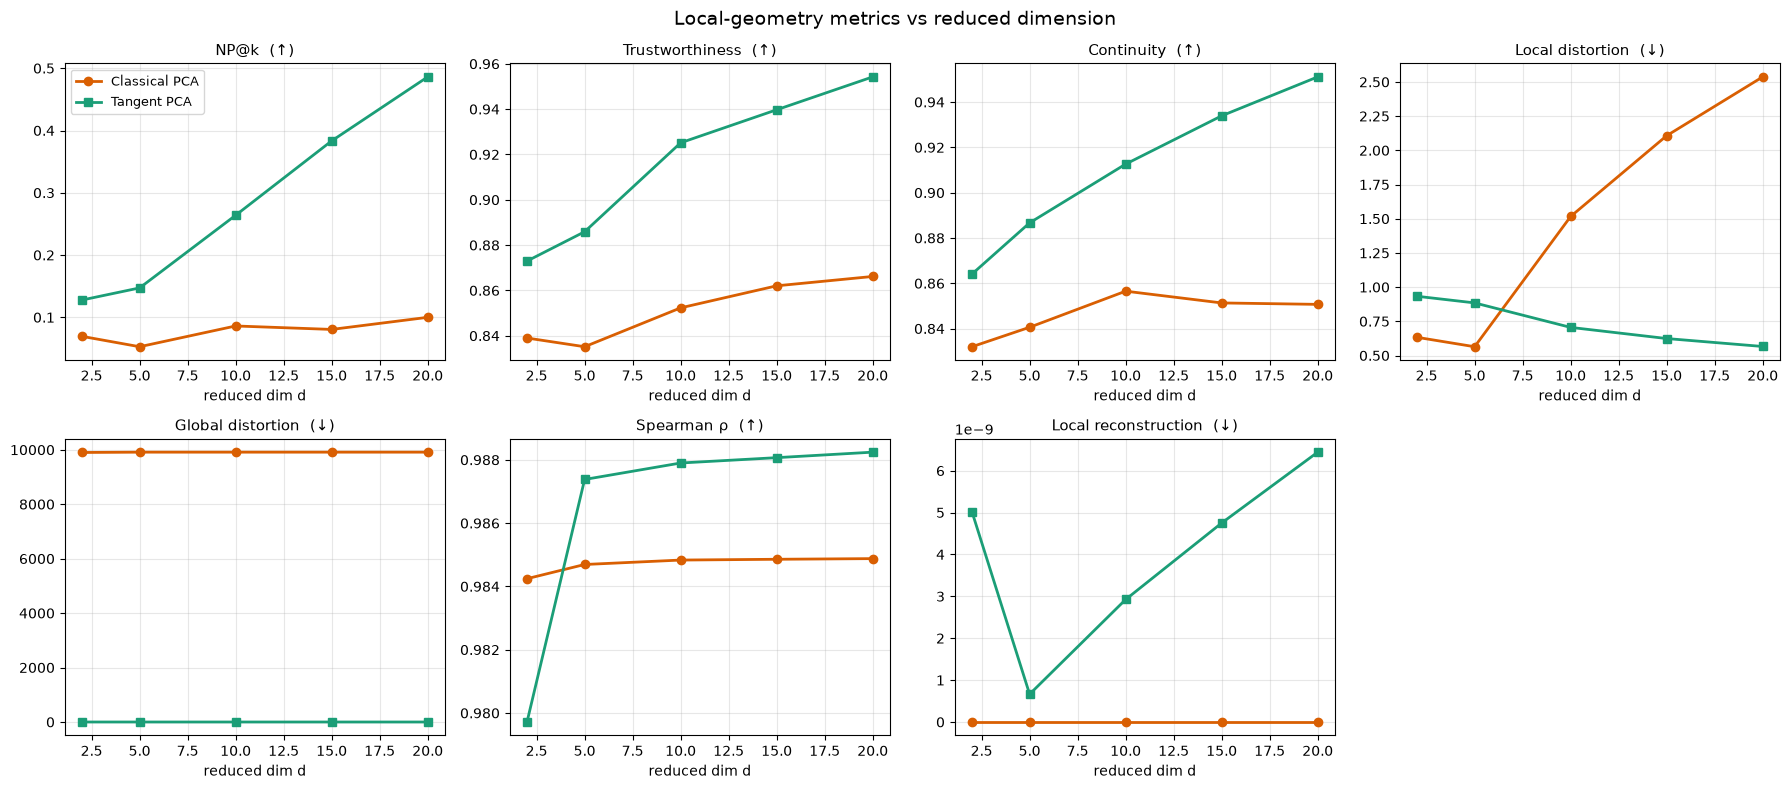

c:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
c:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\manifold\_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


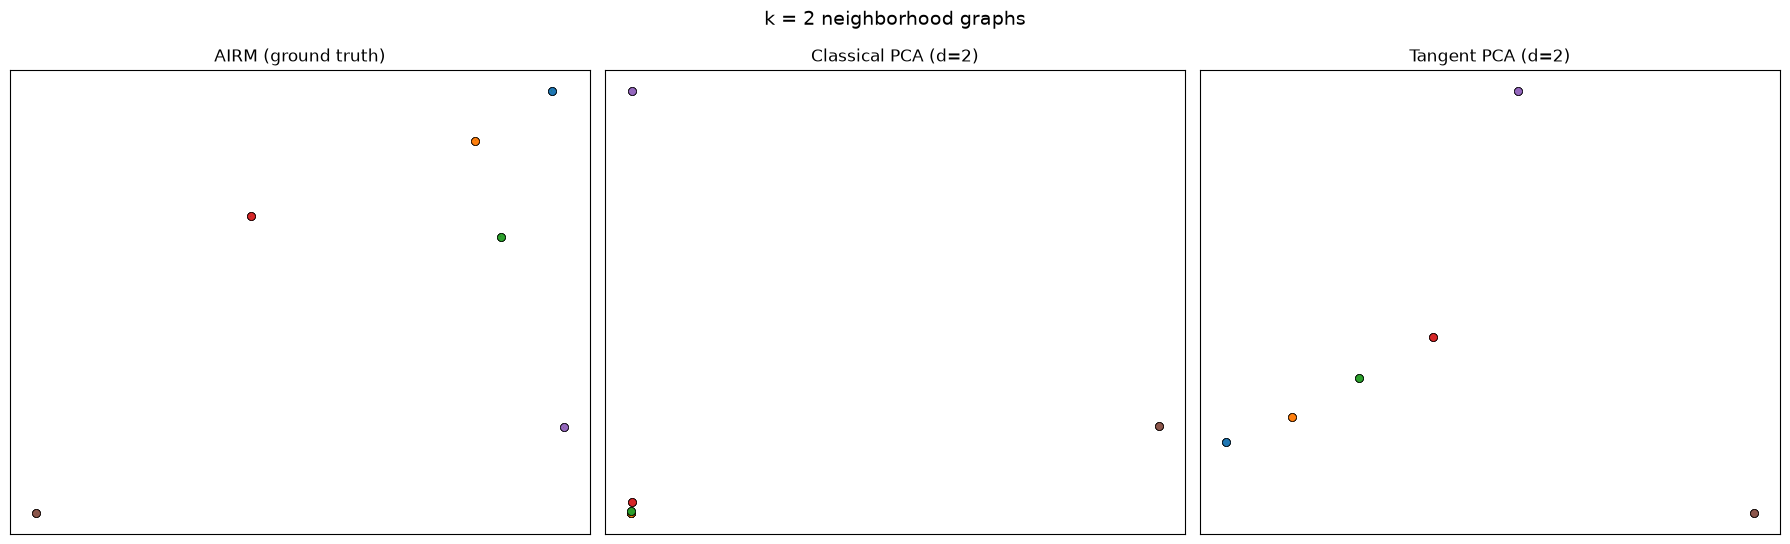

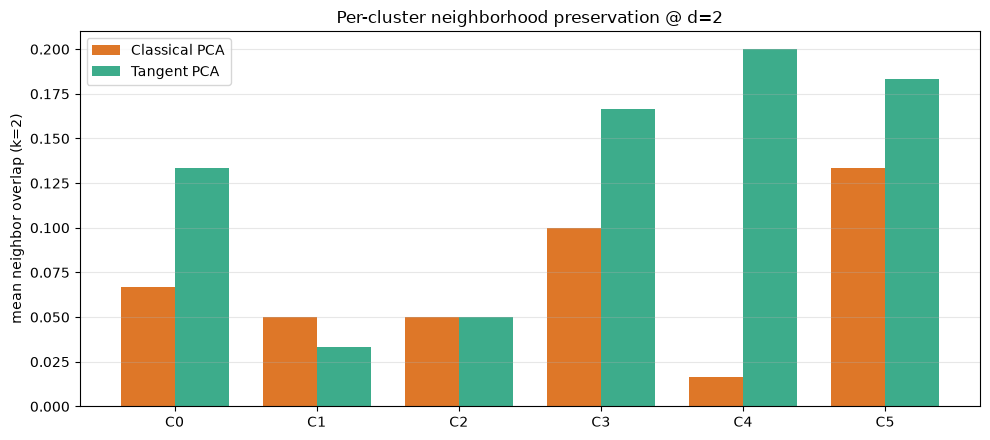

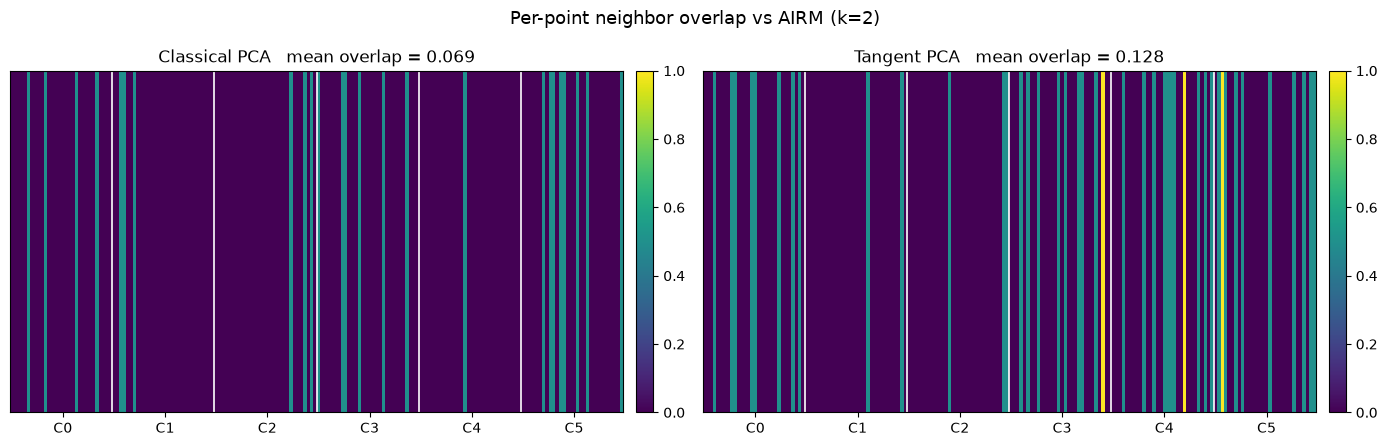


SUMMARY — head-to-head at d = 2  vs  d = 20

  --- d = 2 ---
  Classical PCA   NP@k=0.0694  Tw=0.8390  Cont=0.8320  LocD=0.6331  Spear=0.9842  Recon=2.19e-17
  Tangent PCA     NP@k=0.1278  Tw=0.8730  Cont=0.8641  LocD=0.9331  Spear=0.9797  Recon=5.02e-09

  --- d = 20 ---
  Classical PCA   NP@k=0.1000  Tw=0.8662  Cont=0.8507  LocD=2.5370  Spear=0.9849  Recon=4.67e-16
  Tangent PCA     NP@k=0.4861  Tw=0.9542  Cont=0.9511  LocD=0.5660  Spear=0.9882  Recon=6.44e-09


: 

In [ ]:
# ============================================================
# LOCAL GEOMETRY & NEIGHBORHOOD PRESERVATION FOR SPD REDUCTION
# Classical PCA vs Tangent PCA — AIRM reference geometry
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr
from sklearn.manifold import MDS

# ------------------------------------------------------------
# Numerical safety constants
# ------------------------------------------------------------
FLOOR     = 1e-12    # eigenvalue floor for every eigh() call
MEAN_EPS  = 1e-6     # ridge added to Fréchet mean / reconstruction
K_NN      = 2       # neighborhood size for metrics
DIMS      = [2, 5, 10, 15, 20]   # reduced dimensions to test
SEED      = 42

# ============================================================
# 1. SYNTHETIC SPD DATASET  (28 x 28, multiple clusters)
# ============================================================
def _random_spd(dim, cond, rng):
    """SPD matrix with target condition number, strictly PD."""
    Q, _ = np.linalg.qr(rng.standard_normal((dim, dim)))
    lam  = np.logspace(0, np.log10(cond), dim)     # eigenvalues 1 .. cond
    M = (Q * lam) @ Q.T
    M = 0.5 * (M + M.T)
    return M + FLOOR * np.eye(dim)

def generate_spd_dataset(n_per_cluster=30, dim=28, seed=SEED):
    """
    Six clusters with distinct geometric personalities
    (condition numbers 1e0 -> 1e6).
    Labels are stored ONLY for visualization / per-cluster reporting;
    they are never used in any reduction or metric.
    """
    rng = np.random.default_rng(seed)
    conds = [1e0, 1e1, 1e2, 1e3, 1e4, 1e6]
    X, y = [], []
    for c, cond in enumerate(conds):
        base = _random_spd(dim, cond, rng)
        for _ in range(n_per_cluster):
            # small SPD perturbation so every sample is unique
            N = rng.standard_normal((dim, dim)) * (0.02 + 0.01 * c)
            S = base + (N @ N.T) / dim
            S = 0.5 * (S + S.T)
            # re-symmetrize, project to strictly PD
            w, V = np.linalg.eigh(S)
            w = np.clip(w, FLOOR, None)
            S = (V * w) @ V.T
            X.append(S); y.append(c)
    return np.stack(X), np.array(y)

# ============================================================
# 2. SPD PRIMITIVES (all numerically floored)
# ============================================================
def spd_sqrt(M):
    w, V = np.linalg.eigh(M); w = np.clip(w, FLOOR, None)
    return (V * np.sqrt(w)) @ V.T

def spd_inv_sqrt(M):
    w, V = np.linalg.eigh(M); w = np.clip(w, FLOOR, None)
    return (V / np.sqrt(w)) @ V.T

def spd_log(M):
    w, V = np.linalg.eigh(M); w = np.clip(w, FLOOR, None)
    return (V * np.log(w)) @ V.T

def airm_dist(P, Q):
    """Affine-Invariant Riemannian distance, with log-Euclid fallback."""
    Pi = spd_inv_sqrt(P)
    M  = Pi @ Q @ Pi
    M  = 0.5 * (M + M.T)
    w, _ = np.linalg.eigh(M); w = np.clip(w, FLOOR, None)
    d = float(np.linalg.norm(np.log(w)))
    if not np.isfinite(d):                        # fallback
        d = float(np.linalg.norm(spd_log(P) - spd_log(Q)))
    return d

def airm_pairwise(X):
    N = len(X)
    D = np.zeros((N, N))
    for i in range(N):
        for j in range(i + 1, N):
            D[i, j] = D[j, i] = airm_dist(X[i], X[j])
    return D

def frechet_mean(mats, tol=1e-9, max_iter=60):
    """Regularized affine-invariant Karcher mean (never hits cone boundary)."""
    M = mats.mean(0) + MEAN_EPS * np.eye(mats.shape[1])
    for _ in range(max_iter):
        Ms, Mi = spd_sqrt(M), spd_inv_sqrt(M)
        T = np.mean([spd_log(Mi @ X @ Mi) for X in mats], axis=0)
        w, V = np.linalg.eigh(T)
        M = Ms @ (V * np.exp(w)) @ V.T @ Ms
        M = 0.5 * (M + M.T) + MEAN_EPS * np.eye(M.shape[0])
        if np.linalg.norm(T) < tol:
            break
    return M

# ============================================================
# 3. VECTORIZATION (upper triangle, sqrt(2) off-diagonal)
# ============================================================
def vectorize_sym(M):
    """
    Frobenius-isometric vectorization of a symmetric matrix:
      - diagonal entries kept as-is
      - off-diagonal multiplied by sqrt(2)
    So that <A,B>_F = <vec(A), vec(B)>_Euclid.
    """
    d = M.shape[-1]
    iu = np.triu_indices(d)
    V = M[..., iu[0], iu[1]].copy()
    off = iu[0] != iu[1]
    V[..., off] *= np.sqrt(2.0)
    return V

def vectorize_batch(Ms):
    return np.stack([vectorize_sym(M) for M in Ms])

# ============================================================
# 4. DIMENSIONALITY REDUCTION
# ============================================================
def classical_pca(X, dims=DIMS):
    """
    Classical PCA on Frobenius-isometric vectorization.
    Returns dict {d: Z_d}  with Z_d of shape (N, d).
    """
    V  = vectorize_batch(X)            # N x p (p = d(d+1)/2)
    mu = V.mean(0)
    Vc = V - mu
    # SVD of centered data
    _, S, Vt = np.linalg.svd(Vc, full_matrices=False)
    out = {}
    for d in dims:
        out[d] = Vc @ Vt[:d].T
    return out

def tangent_pca(X, dims=DIMS):
    """
    Tangent PCA:
      1) Fréchet mean M*
      2) Log-map: T_i = log(M*^{-1/2} X_i M*^{-1/2})
      3) Vectorize T_i (Frobenius-isometric)
      4) Center + PCA
    """
    N, dim, _ = X.shape
    m  = frechet_mean(X)
    mi = spd_inv_sqrt(m)
    T  = np.stack([spd_log(mi @ X[i] @ mi) for i in range(N)])
    V  = vectorize_batch(T)
    mu = V.mean(0)
    Vc = V - mu
    _, S, Vt = np.linalg.svd(Vc, full_matrices=False)
    out = {}
    for d in dims:
        out[d] = Vc @ Vt[:d].T
    return out

# ============================================================
# 5. NEIGHBORHOOD HELPERS
# ============================================================
def knn_from_dist(D, k):
    D2 = D.copy(); np.fill_diagonal(D2, np.inf)
    return np.argsort(D2, axis=1)[:, :k]

def knn_from_points(Z, k):
    return knn_from_dist(cdist(Z, Z), k)

def neighbor_overlap_per_point(knn_a, knn_b):
    n = knn_a.shape[0]; k = knn_a.shape[1]
    return np.array([
        len(set(knn_a[i]) & set(knn_b[i])) / k for i in range(n)
    ])

# ============================================================
# 6. LOCAL GEOMETRY METRICS
# ============================================================
def np_at_k(D_high, Z, k):
    """NP@k : fraction of AIRM neighbors preserved in reduced space."""
    knn_h = knn_from_dist(D_high, k)
    knn_l = knn_from_points(Z, k)
    return float(neighbor_overlap_per_point(knn_h, knn_l).mean())

def trustworthiness(D_high, Z, k):
    """Higher is better. Ranks penalize 'intruders' in reduced k-NN."""
    n = D_high.shape[0]
    knn_h = knn_from_dist(D_high, k)
    D_low = cdist(Z, Z)
    # rank in reduced space (0-based)
    ranks_low = np.argsort(np.argsort(D_low, axis=1), axis=1)
    tw = 0.0
    for i in range(n):
        for r, j in enumerate(knn_h[i]):
            tw += ranks_low[i, j] - r
    denom = n * k * (2 * n - 3 * k - 1) / 2.0
    return 1.0 - 2.0 / max(denom, 1e-12) * tw

def continuity(D_high, Z, k):
    """Higher is better. Symmetric counterpart of trustworthiness."""
    n = D_high.shape[0]
    D_low = cdist(Z, Z)
    knn_l = knn_from_dist(D_low, k)
    ranks_high = np.argsort(np.argsort(D_high, axis=1), axis=1)
    tw = 0.0
    for i in range(n):
        for r, j in enumerate(knn_l[i]):
            tw += ranks_high[i, j] - r
    denom = n * k * (2 * n - 3 * k - 1) / 2.0
    return 1.0 - 2.0 / max(denom, 1e-12) * tw

def distance_distortion(D_high, Z, k):
    """
    Local (k-NN) + global distortion, and Spearman rank correlation.
    - Local relative distortion : mean/median |d_low/d_high - 1| over k-NN pairs.
    - Global relative distortion : same over ALL pairs.
    - Spearman rho : rank agreement between d_high and d_low over all pairs.
    """
    n = D_high.shape[0]
    D_low = cdist(Z, Z)

    # --- local (k-NN) ---
    knn_h = knn_from_dist(D_high, k)
    loc_ratios = []
    for i in range(n):
        for j in knn_h[i]:
            if D_high[i, j] > FLOOR:
                loc_ratios.append(abs(D_low[i, j] / D_high[i, j] - 1.0))
    loc_ratios = np.array(loc_ratios)

    # --- global ---
    iu = np.triu_indices(n, k=1)
    dh = D_high[iu]; dl = D_low[iu]
    mask = dh > FLOOR
    glob_ratios = np.abs(dl[mask] / dh[mask] - 1.0)

    # --- Spearman (all pairs) ---
    rho, _ = spearmanr(dh, dl)

    return {
        "local_mean":    float(loc_ratios.mean()),
        "local_median":  float(np.median(loc_ratios)),
        "global_mean":   float(glob_ratios.mean()),
        "global_median": float(np.median(glob_ratios)),
        "spearman":      float(rho),
    }

def local_reconstruction_error(X, D_high, Z, k):
    """
    LLE-style reconstruction:
      1) For each i, take AIRM k-NN (ground truth neighbors).
      2) Compute LLE weights in the *tangent space around X_i* (AIRM-consistent).
      3) Apply the SAME weights to the reduced vectors Z to reconstruct Z_i.
      4) Error = || Z_i - sum_j w_j Z_j ||^2  (normalized by ||Z_i - Z̄||^2).
    Returns mean reconstruction error over all points.
    """
    n, dim, _ = X.shape
    knn_h = knn_from_dist(D_high, k)
    Zbar  = Z.mean(0)
    errs  = []

    for i in range(n):
        nb = knn_h[i]
        # --- step 1: tangent-space neighbors around X_i (AIRM) ---
        Xi_sqrt = spd_sqrt(X[i])
        Xi_inv  = spd_inv_sqrt(X[i])
        # tangent vectors of neighbors at X_i
        Tnb = np.stack([spd_log(Xi_inv @ X[j] @ Xi_inv) for j in nb])
        Vnb = vectorize_batch(Tnb)                # (k, p)
        # --- step 2: LLE weights (solve C w = 1, sum w = 1) ---
        G = Vnb @ Vnb.T
        # regularization for stability
        G += 1e-8 * np.trace(G) / k * np.eye(k)
        w = np.linalg.solve(G, np.ones(k))
        s = w.sum()
        w = w / s if abs(s) > 1e-12 else np.ones(k) / k
        # --- step 3: reconstruct in reduced space with SAME weights ---
        Zi_hat = w @ Z[nb]
        # --- step 4: normalized error ---
        err = np.linalg.norm(Z[i] - Zi_hat) ** 2
        den = np.linalg.norm(Z[i] - Zbar) ** 2
        errs.append(err / max(den, 1e-12))
    return float(np.mean(errs))

# ============================================================
# 7. RUN EXPERIMENT
# ============================================================
if __name__ == "__main__":
    np.set_printoptions(precision=4, suppress=True)

    X, y = generate_spd_dataset()
    N, dim, _ = X.shape
    print(f"Dataset: N={N} SPD matrices of size {dim}x{dim}, "
          f"{len(np.unique(y))} clusters\n")

    # --- (1) reference AIRM geometry ---------------------------------
    print("Computing AIRM pairwise distances ...")
    D_high = airm_pairwise(X)
    print(f"   mean={D_high[D_high>0].mean():.4f}   max={D_high.max():.4f}\n")

    # --- (2) both reductions for each d ------------------------------
    Zc = classical_pca(X, DIMS)
    Zt = tangent_pca  (X, DIMS)

    # --- (3) metrics per (method, d) --------------------------------
    rows = []
    for d in DIMS:
        for name, Z in [("Classical PCA", Zc[d]), ("Tangent PCA", Zt[d])]:
            dist = distance_distortion(D_high, Z, K_NN)
            rows.append({
                "method":       name,
                "d":            d,
                "NP@k":         np_at_k(D_high, Z, K_NN),
                "Trust":        trustworthiness(D_high, Z, K_NN),
                "Cont":         continuity(D_high, Z, K_NN),
                "LocDistMean":  dist["local_mean"],
                "LocDistMed":   dist["local_median"],
                "GlobDistMean": dist["global_mean"],
                "GlobDistMed":  dist["global_median"],
                "Spearman":     dist["spearman"],
                "LocRecon":     local_reconstruction_error(X, D_high, Z, K_NN),
            })

    # ============================================================
    # 8. REPORT
    # ============================================================
    print("=" * 112)
    print("LOCAL GEOMETRY METRICS  (k = %d)  --  higher NP/Tw/Cont/Spearman = better; "
          "lower distortion/Recon = better" % K_NN)
    print("=" * 112)
    hdr = (f"{'Method':<14}{'d':>3}  {'NP@k':>7}{'Trust':>8}{'Cont':>8}"
           f"{'LocDm':>8}{'LocDmd':>8}{'GlbDm':>8}{'GlbDmd':>8}"
           f"{'Spear':>8}{'Recon':>9}")
    print(hdr); print("-" * len(hdr))
    for r in rows:
        print(f"{r['method']:<14}{r['d']:>3}  "
              f"{r['NP@k']:>7.4f}{r['Trust']:>8.4f}{r['Cont']:>8.4f}"
              f"{r['LocDistMean']:>8.4f}{r['LocDistMed']:>8.4f}"
              f"{r['GlobDistMean']:>8.4f}{r['GlobDistMed']:>8.4f}"
              f"{r['Spearman']:>8.4f}{r['LocRecon']:>9.2e}")
    print("-" * len(hdr))

    # ============================================================
    # 9. FIGURE 1 — metrics vs reduced dimension
    # ============================================================
    metrics = ["NP@k", "Trust", "Cont", "LocDistMean",
               "GlobDistMean", "Spearman", "LocRecon"]
    titles  = ["NP@k  (↑)", "Trustworthiness  (↑)", "Continuity  (↑)",
               "Local distortion  (↓)", "Global distortion  (↓)",
               "Spearman ρ  (↑)", "Local reconstruction  (↓)"]

    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.ravel()
    for ax, met, title in zip(axes, metrics, titles):
        c_vals = [next(r for r in rows if r["method"] == "Classical PCA" and r["d"] == d)[met]
                  for d in DIMS]
        t_vals = [next(r for r in rows if r["method"] == "Tangent PCA"   and r["d"] == d)[met]
                  for d in DIMS]
        ax.plot(DIMS, c_vals, "o-", color="#d95f02", lw=2, label="Classical PCA")
        ax.plot(DIMS, t_vals, "s-", color="#1b9e77", lw=2, label="Tangent PCA")
        ax.set_title(title, fontsize=11); ax.set_xlabel("reduced dim d")
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=9)
    axes[-1].axis("off")
    plt.suptitle("Local-geometry metrics vs reduced dimension", fontsize=14)
    plt.tight_layout(); plt.show()

    # ============================================================
    # 10. FIGURE 2 — neighborhood graphs, d=2 (AIRM vs both methods)
    # ============================================================
    d_plot = 2
    Z_classic = Zc[d_plot]; Z_tangent = Zt[d_plot]
    knn_before = knn_from_dist(D_high, K_NN)
    knn_class  = knn_from_points(Z_classic, K_NN)
    knn_tang   = knn_from_points(Z_tangent, K_NN)

    # MDS of AIRM for display only
    Z_airm = MDS(n_components=2, dissimilarity="precomputed",
                 random_state=0, normalized_stress="auto").fit_transform(D_high)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    palette = [f"C{i}" for i in range(len(np.unique(y)))]

    panels = [
        ("AIRM (ground truth)", Z_airm, knn_before),
        ("Classical PCA (d=2)",  Z_classic, knn_class),
        ("Tangent PCA (d=2)",    Z_tangent, knn_tang),
    ]
    for ax, (title, Z, knn) in zip(axes, panels):
        for c in np.unique(y):
            m = (y == c)
            ax.scatter(Z[m, 0], Z[m, 1], s=30, color=palette[c],
                       edgecolor="k", linewidth=0.3, alpha=0.85)
        segs = [[Z[i], Z[j]] for i in range(N) for j in knn[i]]
        ax.add_collection(LineCollection(segs, colors="grey", alpha=0.25, lw=0.5))
        ax.set_title(title, fontsize=12); ax.set_xticks([]); ax.set_yticks([])
        ax.grid(alpha=0.2)
    plt.suptitle(f"k = {K_NN} neighborhood graphs", fontsize=14)
    plt.tight_layout(); plt.show()

    # ============================================================
    # 11. FIGURE 3 — per-cluster neighbor overlap, d=2
    # ============================================================
    ov_c = neighbor_overlap_per_point(knn_before, knn_class)
    ov_t = neighbor_overlap_per_point(knn_before, knn_tang)
    clusters = np.unique(y)
    per_c = [ov_c[y == c].mean() for c in clusters]
    per_t = [ov_t[y == c].mean() for c in clusters]

    fig, ax = plt.subplots(figsize=(10, 4.5))
    xp = np.arange(len(clusters)); w = 0.38
    ax.bar(xp - w/2, per_c, w, color="#d95f02", alpha=0.85, label="Classical PCA")
    ax.bar(xp + w/2, per_t, w, color="#1b9e77", alpha=0.85, label="Tangent PCA")
    ax.set_xticks(xp); ax.set_xticklabels([f"C{c}" for c in clusters])
    ax.set_ylabel(f"mean neighbor overlap (k={K_NN})")
    ax.set_title("Per-cluster neighborhood preservation @ d=2")
    ax.legend(); ax.grid(alpha=0.3, axis="y")
    plt.tight_layout(); plt.show()

    # ============================================================
    # 12. FIGURE 4 — per-point overlap heatmaps, d=2
    # ============================================================
    order = np.argsort(y, kind="stable")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, (name, ov) in zip(axes, [("Classical PCA", ov_c),
                                     ("Tangent PCA",   ov_t)]):
        im = ax.imshow(ov[order][None, :], aspect="auto",
                       cmap="viridis", vmin=0, vmax=1)
        bounds = np.cumsum(np.bincount(y))
        for b in bounds[:-1]:
            ax.axvline(b - 0.5, color="w", lw=1.2)
        ax.set_yticks([])
        centers = bounds - np.bincount(y) / 2
        ax.set_xticks(centers)
        ax.set_xticklabels([f"C{c}" for c in clusters])
        ax.set_title(f"{name}   mean overlap = {ov.mean():.3f}")
        plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    plt.suptitle(f"Per-point neighbor overlap vs AIRM (k={K_NN})", fontsize=13)
    plt.tight_layout(); plt.show()

    # ============================================================
    # 13. FINAL SUMMARY (d = 2 vs d = 20 head-to-head)
    # ============================================================
    print("\n" + "=" * 72)
    print("SUMMARY — head-to-head at d = 2  vs  d = 20")
    print("=" * 72)
    for d in [2, 20]:
        print(f"\n  --- d = {d} ---")
        for m in ["Classical PCA", "Tangent PCA"]:
            r = next(rr for rr in rows if rr["method"] == m and rr["d"] == d)
            print(f"  {m:<14}  "
                  f"NP@k={r['NP@k']:.4f}  Tw={r['Trust']:.4f}  "
                  f"Cont={r['Cont']:.4f}  LocD={r['LocDistMean']:.4f}  "
                  f"Spear={r['Spearman']:.4f}  Recon={r['LocRecon']:.2e}")